# Segmentation Statistical Analysis

### Paired Per-Image Statistical Analysis

This cell evaluates the five segmentation configurations across five independent runs (Seeds 41–45) using the saved model checkpoints.

For each run, pixel-level predictions are generated on the validation set, and per-image Dice scores are calculated. The mean, standard deviation, and median Dice are then recorded for each run.

The per-image Dice scores from the five runs are averaged to obtain one Dice value per validation image for each model. These values are used for paired comparisons between the segmentation configurations using the Wilcoxon signed-rank test, followed by Holm correction for multiple comparisons.

The cell reports the five-run summary statistics and individual run results. It also saves the per-image Dice values and statistical test results for subsequent analysis and visualization.

In [ ]:
# ============================================================
# PAIRED PER-IMAGE STATISTICAL ANALYSIS
# 5 RUNS × 5 SEGMENTATION CONFIGURATIONS
#
# This cell:
# 1. Creates the five model architectures.
# 2. Creates the corresponding validation loaders.
# 3. Loads all 25 trained checkpoints.
# 4. Extracts per-image Dice scores.
# 5. Calculates run-level mean, SD, and median Dice.
# 6. Averages the five runs for each validation image.
# 7. Performs paired Wilcoxon signed-rank tests.
# 8. Applies Holm correction for multiple comparisons.
# 9. Saves the statistical results and per-image Dice values.
# ============================================================

import os
import copy
import warnings
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. CONFIGURATIONS
# ============================================================

CONFIGS = [
    "2D_Baseline",
    "2.5D_Baseline",
    "2.5D_EncAtt",
    "2.5D_DecAtt",
    "2.5D_FullAtt",
]

SEEDS = [41, 42, 43, 44, 45]


# ============================================================
# 2. MODEL CONFIGURATION
# ============================================================

MODEL_SETTINGS = {
    "2D_Baseline": {
        "in_ch": 1,
        "use_enc_att": False,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_Baseline": {
        "in_ch": 3,
        "use_enc_att": False,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_EncAtt": {
        "in_ch": 3,
        "use_enc_att": True,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_DecAtt": {
        "in_ch": 3,
        "use_enc_att": False,
        "use_dec_att": True,
        "use_low_att": False,
    },

    # This configuration matches the architecture used during training.
    "2.5D_FullAtt": {
        "in_ch": 3,
        "use_enc_att": True,
        "use_dec_att": True,
        "use_low_att": False,
    },
}


# ============================================================
# 3. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "val_ids",
    "AblationDataset",
    "SwinUNetAdaptive_DS",
    "BATCH_SIZE",
    "NUM_WORKERS",
    "PATCH_SIZE",
    "IN_CHANNELS",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables/classes are missing:\n"
        + "\n".join(f"  - {variable}" for variable in missing_variables)
    )

print("All required variables are available.")


# ============================================================
# 4. CHECKPOINT PATHS
# ============================================================

CHECKPOINT_DIR = Path(r"Checkpoints\AllChekoints_140506")

CHECKPOINT_FILENAMES = {
    "2D_Baseline": "best_model_Baseline_2D_S{seed}.pt",
    "2.5D_Baseline": "best_model_Baseline_2.5D_S{seed}.pt",
    "2.5D_EncAtt": "best_model_2.5D_EncAtt_S{seed}.pt",
    "2.5D_DecAtt": "best_model_2.5D_DecAtt_S{seed}.pt",
    "2.5D_FullAtt": "best_model_2.5D_FullAtt_S{seed}.pt",
}

CHECKPOINTS = {
    config: {
        seed: CHECKPOINT_DIR / CHECKPOINT_FILENAMES[config].format(seed=seed)
        for seed in SEEDS
    }
    for config in CONFIGS
}


# ============================================================
# 5. CHECK ALL CHECKPOINTS
# ============================================================

missing_checkpoints = []

for config in CONFIGS:
    for seed in SEEDS:
        checkpoint_path = CHECKPOINTS[config][seed]

        if not checkpoint_path.is_file():
            missing_checkpoints.append(
                f"{config} | Seed {seed} | {checkpoint_path.name}"
            )

if missing_checkpoints:
    raise FileNotFoundError(
        "The following checkpoints were not found:\n"
        + "\n".join(missing_checkpoints)
    )

print("All 25 checkpoints were found.")


# ============================================================
# 6. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# 7. CREATE MODEL ARCHITECTURES
# ============================================================

models = {}

for config in CONFIGS:

    settings = MODEL_SETTINGS[config]

    model = SwinUNetAdaptive_DS(
        in_ch=settings["in_ch"],
        base="timm",
        out_ch=1,
        use_enc_att=settings["use_enc_att"],
        use_dec_att=settings["use_dec_att"],
        use_low_att=settings["use_low_att"],
        att_combine_method="max",
        patch_size=PATCH_SIZE,
    )

    models[config] = model

    print(f"Created architecture: {config}")

print("All model architectures were created.")


# ============================================================
# 8. CREATE VALIDATION LOADERS
# ============================================================

loaders = {}

for config in CONFIGS:

    use_25d = MODEL_SETTINGS[config]["in_ch"] == 3

    ds_val = AblationDataset(
        val_ids,
        train=False,
        use_25d=use_25d,
        crop_mode="random",
        use_crop=False,
    )

    val_loader = DataLoader(
        ds_val,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    loaders[config] = val_loader

    print(
        f"{config}: "
        f"use_25d={use_25d}, "
        f"validation samples={len(ds_val):,}"
    )


# ============================================================
# 9. DICE FUNCTION
# ============================================================

def dice_score(y_true, y_pred, eps=1e-8):

    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    intersection = np.logical_and(
        y_true,
        y_pred
    ).sum()

    return (
        2.0 * intersection
        / (
            y_true.sum()
            + y_pred.sum()
            + eps
        )
    )


# ============================================================
# 10. LOAD CHECKPOINT
# ============================================================

def load_checkpoint(model, checkpoint_path, device):

    # The checkpoints are trusted files created by this project.
    # Suppress the FutureWarning while preserving the original loading behavior.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=FutureWarning,
            message="You are using `torch.load`"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False,
        )

    if isinstance(checkpoint, dict):

        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]

        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]

        elif (
            "model" in checkpoint
            and isinstance(checkpoint["model"], dict)
        ):
            state_dict = checkpoint["model"]

        else:
            state_dict = checkpoint

    else:
        state_dict = checkpoint

    cleaned_state_dict = {}

    for key, value in state_dict.items():

        if key.startswith("module."):
            key = key[len("module."):]

        cleaned_state_dict[key] = value

    # Strict loading prevents evaluation with randomly initialized parameters.
    model.load_state_dict(
        cleaned_state_dict,
        strict=True,
    )

    return model


# ============================================================
# 11. EXTRACT PER-IMAGE DICE
# ============================================================

def collect_validation_dice(model, val_loader, device):

    model.eval()

    all_dice = []

    with torch.inference_mode():

        for x, y in val_loader:

            x = x.to(
                device,
                non_blocking=True,
            )

            output = model(x)

            if isinstance(output, (tuple, list)):
                output = output[0]

            probability = torch.sigmoid(output)
            prediction = probability > 0.5

            prediction = (
                prediction.detach()
                .cpu()
                .numpy()
            )

            y = (
                y.detach()
                .cpu()
                .numpy()
            )

            for i in range(len(y)):

                dice = dice_score(
                    y[i],
                    prediction[i],
                )

                all_dice.append(dice)

    return np.asarray(
        all_dice,
        dtype=np.float64,
    )


# ============================================================
# 12. EVALUATE ALL 25 CHECKPOINTS
# ============================================================

dice_runs = {
    config: {}
    for config in CONFIGS
}

run_summary = {
    config: {}
    for config in CONFIGS
}

for config in CONFIGS:

    print("\n" + "=" * 80)
    print(f"Configuration: {config}")
    print("=" * 80)

    base_model = models[config]
    val_loader = loaders[config]

    for seed in SEEDS:

        print(f"\nEvaluating {config}, Seed {seed} ...")

        model = copy.deepcopy(base_model).to(device)

        model = load_checkpoint(
            model,
            CHECKPOINTS[config][seed],
            device,
        )

        dices = collect_validation_dice(
            model,
            val_loader,
            device,
        )

        if len(dices) == 0:
            raise RuntimeError(
                f"No validation predictions were collected for "
                f"{config}, Seed {seed}."
            )

        dice_runs[config][seed] = dices

        run_mean = dices.mean() * 100
        run_sd = dices.std(ddof=1) * 100
        run_median = np.median(dices) * 100

        run_summary[config][seed] = {
            "mean": run_mean,
            "sd": run_sd,
            "median": run_median,
        }

        print(
            f"Seed {seed}: "
            f"N = {len(dices):,}, "
            f"Mean Dice = {run_mean:.4f}%, "
            f"SD = {run_sd:.4f}%, "
            f"Median Dice = {run_median:.4f}%"
        )

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 13. CHECK VALIDATION-SET CONSISTENCY
# ============================================================

print("\n" + "=" * 80)
print("CHECKING VALIDATION-SET CONSISTENCY")
print("=" * 80)

for config in CONFIGS:

    lengths = [
        len(dice_runs[config][seed])
        for seed in SEEDS
    ]

    print(f"{config}: {lengths}")

    if len(set(lengths)) != 1:
        raise RuntimeError(
            f"Validation-set size differs across runs for {config}."
        )

    if len(lengths) != 5:
        raise RuntimeError(
            f"Expected five runs for {config}, but found {len(lengths)}."
        )


# ============================================================
# 14. AVERAGE THE FIVE RUNS FOR EACH IMAGE
# ============================================================

mean_dice_per_image = {}

for config in CONFIGS:

    run_matrix = np.stack(
        [
            dice_runs[config][seed]
            for seed in SEEDS
        ],
        axis=0,
    )

    if run_matrix.ndim != 2:
        raise RuntimeError(
            f"Unexpected matrix shape for {config}: {run_matrix.shape}"
        )

    mean_dice_per_image[config] = run_matrix.mean(axis=0)

    print(
        f"{config}: "
        f"run matrix={run_matrix.shape}, "
        f"per-image results={mean_dice_per_image[config].shape}"
    )


# ============================================================
# 15. CHECK THAT ALL MODELS USE THE SAME VALIDATION IMAGES
# ============================================================

validation_lengths = [
    len(mean_dice_per_image[config])
    for config in CONFIGS
]

if len(set(validation_lengths)) != 1:
    raise RuntimeError(
        "The models do not have the same number of validation images."
    )

N_VALIDATION = validation_lengths[0]

print(
    f"\nAll models were evaluated on "
    f"{N_VALIDATION:,} validation images."
)


# ============================================================
# 16. FIVE-RUN SUMMARY
# ============================================================

summary_rows = []

for config in CONFIGS:

    run_means = np.array([
        run_summary[config][seed]["mean"]
        for seed in SEEDS
    ])

    run_medians = np.array([
        run_summary[config][seed]["median"]
        for seed in SEEDS
    ])

    mean_across_runs = run_means.mean()
    sd_across_runs = run_means.std(ddof=1)

    median_across_runs = run_medians.mean()
    sd_median_across_runs = run_medians.std(ddof=1)

    summary_rows.append({
        "Model": config,
        "N": N_VALIDATION,
        "Mean Dice (%)": mean_across_runs,
        "SD Mean Dice (%)": sd_across_runs,
        "Mean Dice ± SD": (
            f"{mean_across_runs:.2f} ± {sd_across_runs:.2f}%"
        ),
        "Median Dice (%)": median_across_runs,
        "SD Median Dice (%)": sd_median_across_runs,
        "Median Dice ± SD": (
            f"{median_across_runs:.2f} ± "
            f"{sd_median_across_runs:.2f}%"
        ),
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 100)
print("FIVE-RUN DICE SUMMARY")
print("=" * 100)

display(
    summary_df[
        [
            "Model",
            "N",
            "Mean Dice ± SD",
            "Median Dice ± SD",
        ]
    ]
)


# ============================================================
# 17. INDIVIDUAL RUN RESULTS
# ============================================================

run_rows = []

for config in CONFIGS:

    for seed in SEEDS:

        run_rows.append({
            "Model": config,
            "Seed": seed,
            "Mean Dice (%)": run_summary[config][seed]["mean"],
            "SD across images (%)": run_summary[config][seed]["sd"],
            "Median Dice (%)": run_summary[config][seed]["median"],
        })

run_summary_df = pd.DataFrame(run_rows)

print("\n" + "=" * 100)
print("INDIVIDUAL RUN RESULTS")
print("=" * 100)

display(run_summary_df)


# ============================================================
# 18. PAIRED WILCOXON SIGNED-RANK TESTS
# ============================================================

comparisons = [
    ("2D_Baseline", "2.5D_Baseline"),
    ("2.5D_Baseline", "2.5D_EncAtt"),
    ("2.5D_Baseline", "2.5D_DecAtt"),
    ("2.5D_Baseline", "2.5D_FullAtt"),
    ("2.5D_DecAtt", "2.5D_FullAtt"),
]

wilcoxon_rows = []

for model_a, model_b in comparisons:

    a = mean_dice_per_image[model_a]
    b = mean_dice_per_image[model_b]

    if len(a) != len(b):
        raise RuntimeError(
            f"Different validation sizes: {model_a} vs {model_b}"
        )

    # Positive differences indicate higher Dice for model_b.
    differences = b - a

    nonzero = int(np.count_nonzero(differences))

    if nonzero == 0:
        statistic = 0.0
        p_value = 1.0

    else:
        statistic, p_value = wilcoxon(
            b,
            a,
            alternative="two-sided",
            zero_method="wilcox",
            method="auto",
        )

    wilcoxon_rows.append({
        "Comparison": f"{model_b} vs {model_a}",
        "N images": len(a),
        "Non-zero pairs": nonzero,
        "Mean difference (%)": differences.mean() * 100,
        "Median difference (%)": np.median(differences) * 100,
        "Wilcoxon statistic": statistic,
        "Raw p-value": p_value,
    })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)


# ============================================================
# 19. HOLM CORRECTION
# ============================================================

reject, p_holm, _, _ = multipletests(
    wilcoxon_df["Raw p-value"].values,
    alpha=0.05,
    method="holm",
)

wilcoxon_df["Holm-adjusted p-value"] = p_holm
wilcoxon_df["Significant (Holm, alpha=0.05)"] = reject


# ============================================================
# 20. DISPLAY STATISTICAL RESULTS
# ============================================================

print("\n" + "=" * 110)
print("PAIRED WILCOXON SIGNED-RANK TEST WITH HOLM CORRECTION")
print("=" * 110)

display(
    wilcoxon_df.style.format({
        "Mean difference (%)": "{:.4f}",
        "Median difference (%)": "{:.4f}",
        "Wilcoxon statistic": "{:.4f}",
        "Raw p-value": "{:.6g}",
        "Holm-adjusted p-value": "{:.6g}",
    })
)


# ============================================================
# 21. SAVE RESULTS
# ============================================================

summary_df.to_csv(
    "segmentation_five_run_dice_summary.csv",
    index=False,
)

wilcoxon_df.to_csv(
    "segmentation_paired_wilcoxon_holm_results.csv",
    index=False,
)

run_summary_df.to_csv(
    "segmentation_individual_run_summary.csv",
    index=False,
)

per_image_df = pd.DataFrame({
    config: mean_dice_per_image[config]
    for config in CONFIGS
})

per_image_df.insert(
    0,
    "Validation_Image_Index",
    np.arange(1, len(per_image_df) + 1),
)

per_image_df.to_csv(
    "segmentation_per_image_dice_all_models.csv",
    index=False,
)

print("\nResults saved:")
print("  segmentation_five_run_dice_summary.csv")
print("  segmentation_paired_wilcoxon_holm_results.csv")
print("  segmentation_individual_run_summary.csv")
print("  segmentation_per_image_dice_all_models.csv")

print("\n" + "=" * 80)
print("STATISTICAL ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 80)

All required variables are available.
All 25 checkpoints were found.
Using device: cuda
Created architecture: 2D_Baseline
Created architecture: 2.5D_Baseline
Created architecture: 2.5D_EncAtt
Created architecture: 2.5D_DecAtt
Created architecture: 2.5D_FullAtt
All model architectures were created.
2D_Baseline: use_25d=False, validation samples=2,082
2.5D_Baseline: use_25d=True, validation samples=2,082
2.5D_EncAtt: use_25d=True, validation samples=2,082
2.5D_DecAtt: use_25d=True, validation samples=2,082
2.5D_FullAtt: use_25d=True, validation samples=2,082

Configuration: 2D_Baseline

Evaluating 2D_Baseline, Seed 41 ...
Seed 41: N = 2,082, Mean Dice = 59.4594%, SD = 35.3750%, Median Dice = 77.6839%

Evaluating 2D_Baseline, Seed 42 ...
Seed 42: N = 2,082, Mean Dice = 59.7246%, SD = 34.5568%, Median Dice = 76.4275%

Evaluating 2D_Baseline, Seed 43 ...
Seed 43: N = 2,082, Mean Dice = 58.0511%, SD = 33.7406%, Median Dice = 72.8942%

Evaluating 2D_Baseline, Seed 44 ...
Seed 44: N = 2,082, M

,Model,N,Mean Dice ± SD,Median Dice ± SD
0,2D_Baseline,2082,59.46 ± 0.90%,76.26 ± 1.95%
1,2.5D_Baseline,2082,62.42 ± 1.84%,78.47 ± 2.06%
2,2.5D_EncAtt,2082,62.16 ± 1.65%,78.48 ± 1.20%
3,2.5D_DecAtt,2082,65.75 ± 1.74%,81.58 ± 1.05%
4,2.5D_FullAtt,2082,66.44 ± 2.58%,81.31 ± 1.86%



INDIVIDUAL RUN RESULTS


,Model,Seed,Mean Dice (%),SD across images (%),Median Dice (%)
0,2D_Baseline,41,59.459441,35.374983,77.683872
1,2D_Baseline,42,59.724604,34.556792,76.427503
2,2D_Baseline,43,58.051062,33.740586,72.894172
3,2D_Baseline,44,59.516318,35.304447,77.488739
4,2D_Baseline,45,60.540037,33.647029,76.825230
5,2.5D_Baseline,41,61.250038,34.405862,78.382353
6,2.5D_Baseline,42,65.520153,32.527487,80.654072
7,2.5D_Baseline,43,62.244177,34.232692,79.471664
8,2.5D_Baseline,44,60.841096,33.078462,75.130904
9,2.5D_Baseline,45,62.223194,33.485393,78.695035



PAIRED WILCOXON SIGNED-RANK TEST WITH HOLM CORRECTION


,Comparison,N images,Non-zero pairs,Mean difference (%),Median difference (%),Wilcoxon statistic,Raw p-value,Holm-adjusted p-value,"Significant (Holm, alpha=0.05)"
0,2.5D_Baseline vs 2D_Baseline,2082,1941,2.9574,0.5975,681925.0000,5.3162e-26,1.59486e-25,True
1,2.5D_EncAtt vs 2.5D_Baseline,2082,1934,-0.2531,0.0000,854904.0000,0.0010224,0.00204479,True
2,2.5D_DecAtt vs 2.5D_Baseline,2082,1939,3.3362,1.3036,506889.0000,3.37741e-69,1.35096e-68,True
3,2.5D_FullAtt vs 2.5D_Baseline,2082,1957,4.0259,1.1484,486133.0000,1.94618e-79,9.73089e-79,True
4,2.5D_FullAtt vs 2.5D_DecAtt,2082,1956,0.6897,0.0000,942474.0000,0.561662,0.561662,False



Results saved:
  segmentation_five_run_dice_summary.csv
  segmentation_paired_wilcoxon_holm_results.csv
  segmentation_individual_run_summary.csv
  segmentation_per_image_dice_all_models.csv

STATISTICAL ANALYSIS COMPLETED SUCCESSFULLY


--------------------------

### Table 7 — Per-Image Dice Summary

This cell generates **Table 7** using the results obtained from the five independent runs (Seeds 41–45).

For each segmentation model, the mean and median Dice scores are calculated separately for each run. The final values are reported as the mean ± standard deviation (SD) across the five runs.

The table summarizes the per-image segmentation performance of the five configurations using Mean Dice and Median Dice.

In [ ]:
# ============================================================
# TABLE 7: PER-IMAGE DICE SUMMARY
# Mean ± SD Across Five Independent Runs
# ============================================================

import pandas as pd
import numpy as np

table7_rows = []

for config in CONFIGS:

    run_means = np.array([
        run_summary[config][seed]["mean"]
        for seed in SEEDS
    ])

    run_medians = np.array([
        run_summary[config][seed]["median"]
        for seed in SEEDS
    ])

    mean_dice = run_means.mean()
    sd_mean_dice = run_means.std(ddof=1)

    median_dice = run_medians.mean()
    sd_median_dice = run_medians.std(ddof=1)

    table7_rows.append({
        "Model": config,
        "Mean Dice": f"{mean_dice:.2f} ± {sd_mean_dice:.2f}%",
        "Median Dice": f"{median_dice:.2f} ± {sd_median_dice:.2f}%",
    })

table7_df = pd.DataFrame(table7_rows)

print("=" * 80)
print("TABLE 7 — PER-IMAGE DICE SUMMARY")
print("=" * 80)

display(table7_df)

TABLE 7 — PER-IMAGE DICE SUMMARY


,Model,Mean Dice,Median Dice
0,2D_Baseline,59.46 ± 0.90%,76.26 ± 1.95%
1,2.5D_Baseline,62.42 ± 1.84%,78.47 ± 2.06%
2,2.5D_EncAtt,62.16 ± 1.65%,78.48 ± 1.20%
3,2.5D_DecAtt,65.75 ± 1.74%,81.58 ± 1.05%
4,2.5D_FullAtt,66.44 ± 2.58%,81.31 ± 1.86%


-------------------------

### Figure 6 — Per-Image Dice Distribution Across Segmentation Models

This cell generates **Figure 6** using the actual per-image Dice scores averaged across the five independent runs (Seeds 41–45).

The boxplots illustrate the distribution of Dice scores across the validation images for the five segmentation configurations. The red dashed line represents the mean Dice score, while the black solid line indicates the median.

The figure provides a visual comparison of the central tendency and variability of per-image segmentation performance across the evaluated models.

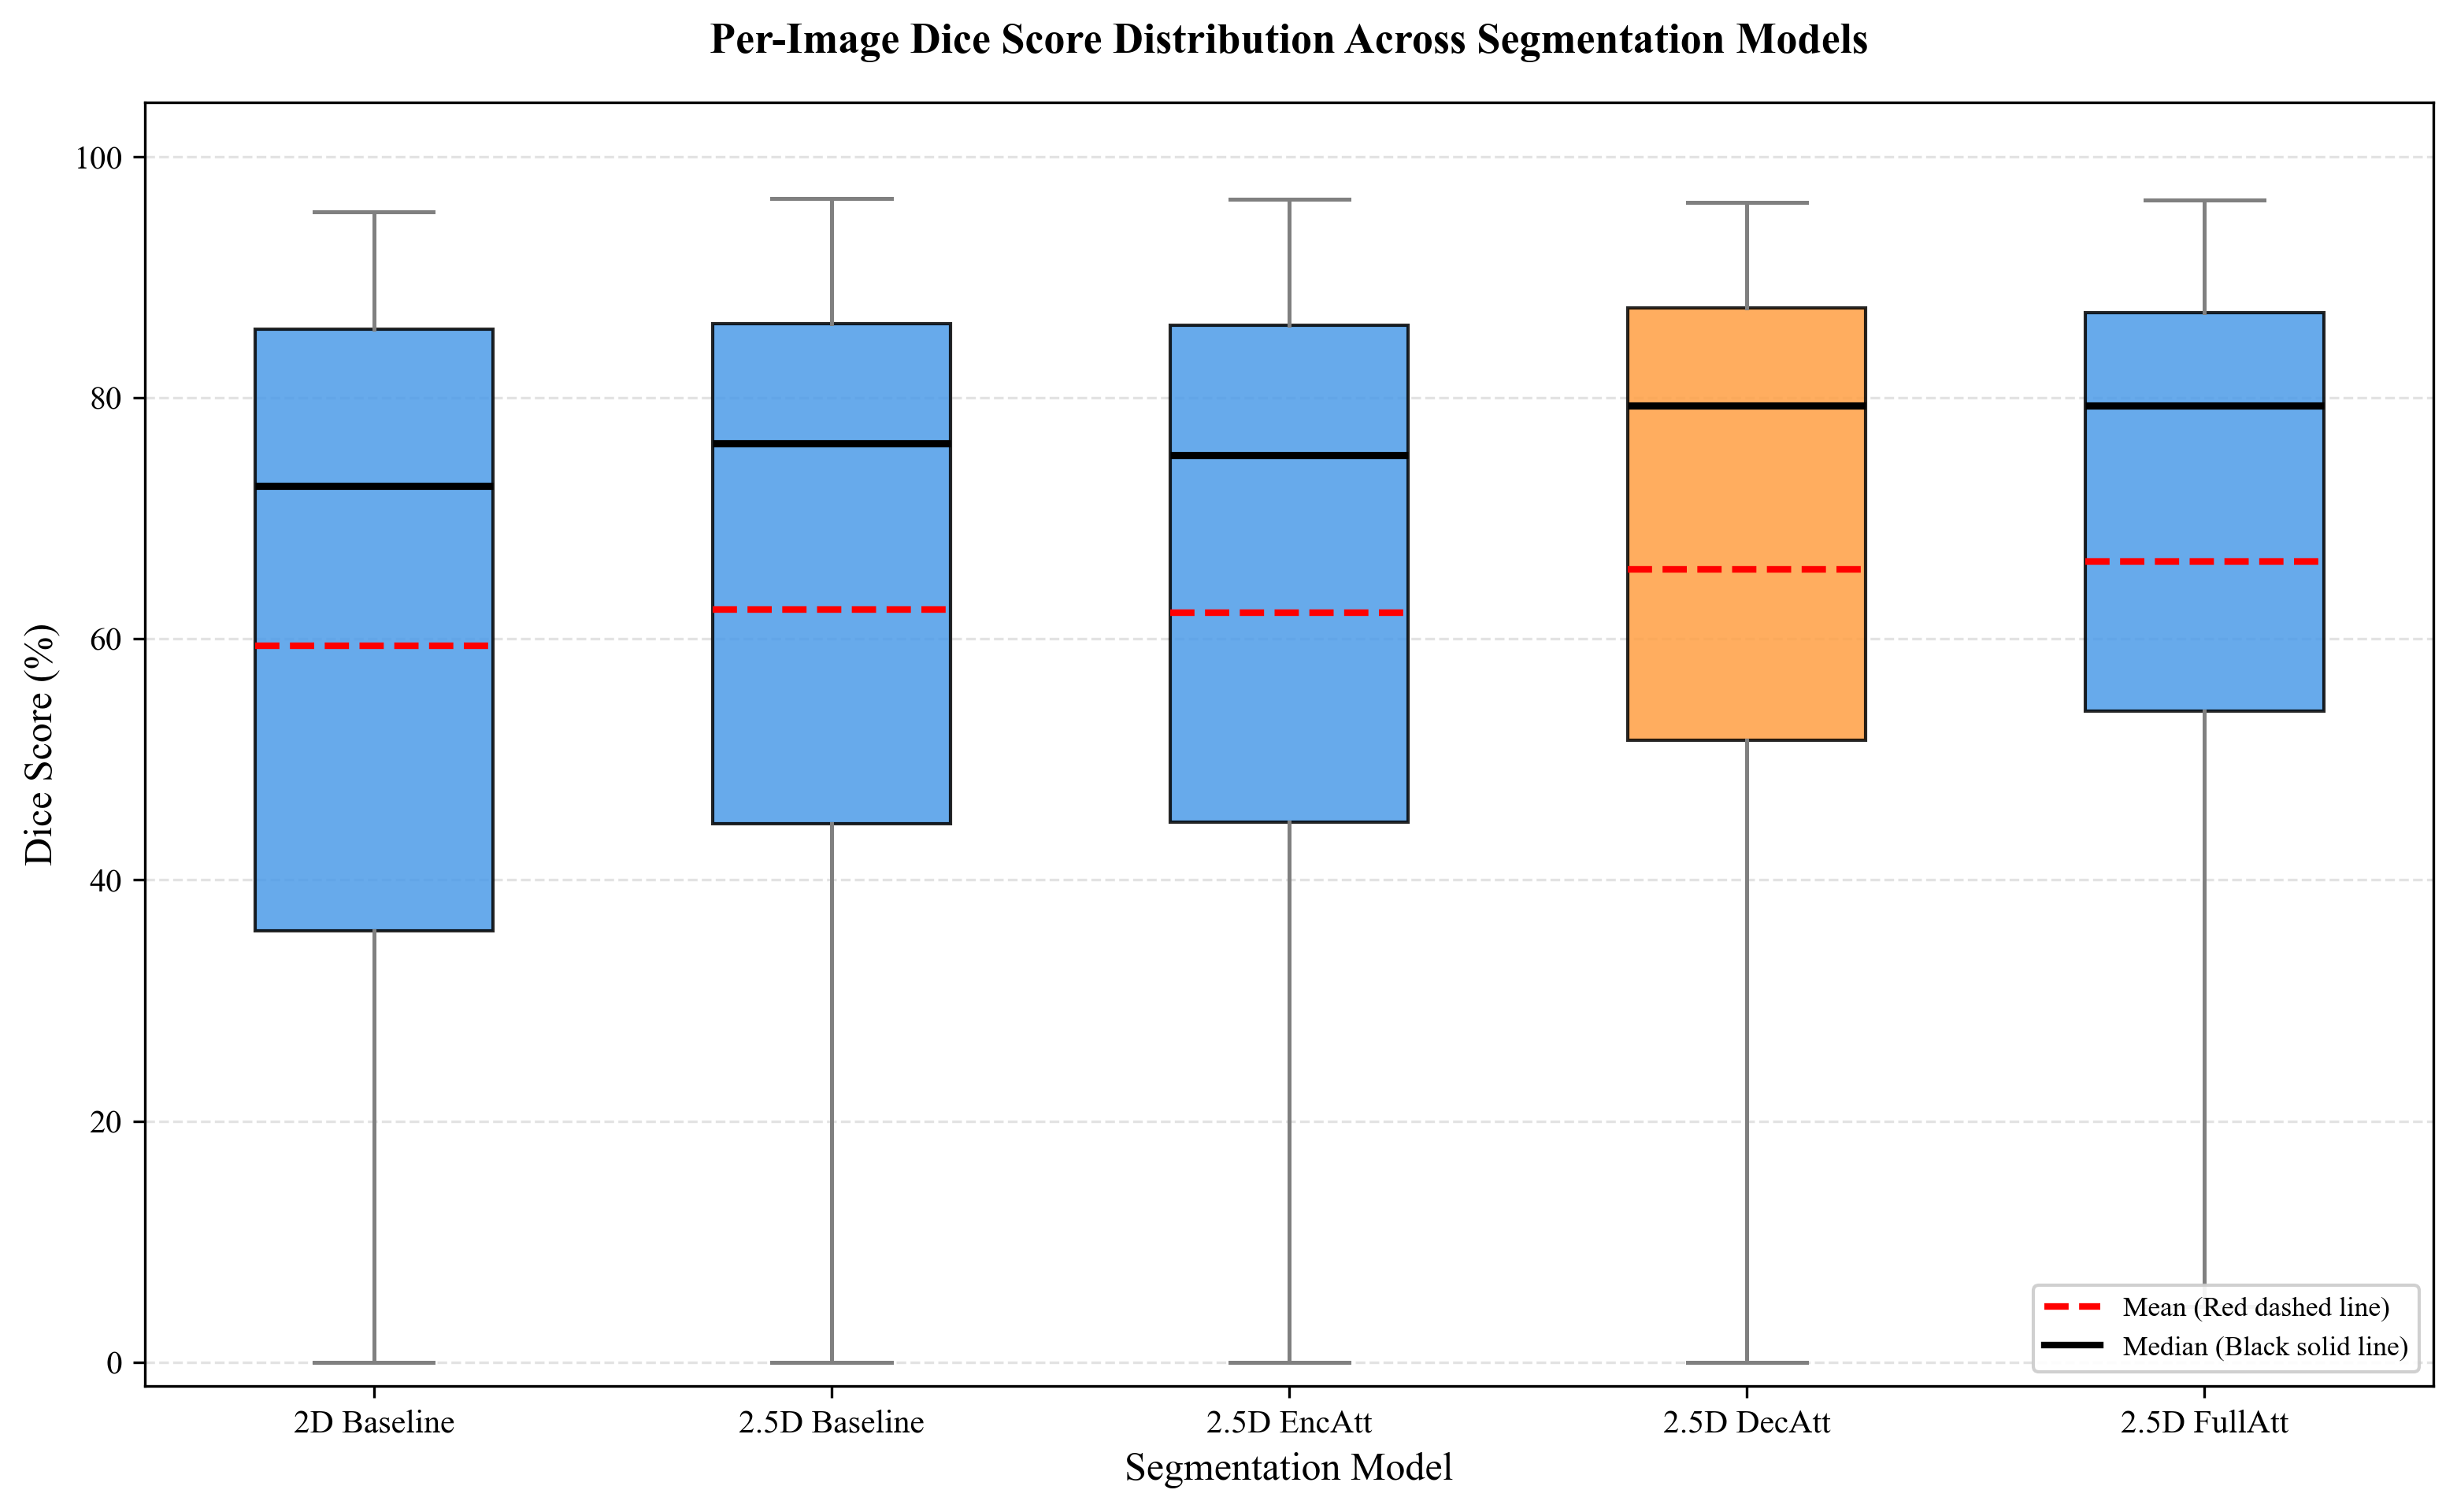

Successfully generated: Figure_6_Per_Image_Dice_Distribution_No_Pvalues.png


In [ ]:
# ============================================================
# FIGURE 6: PER-IMAGE DICE DISTRIBUTION
# Mean and Median Lines — No Significance Brackets
# ============================================================

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import warnings

warnings.filterwarnings("ignore")
# ============================================================
# 1. MODEL ORDER
# ============================================================

plot_order = [
    "2D_Baseline",
    "2.5D_Baseline",
    "2.5D_EncAtt",
    "2.5D_DecAtt",
    "2.5D_FullAtt",
]

plot_labels = [
    "2D Baseline",
    "2.5D Baseline",
    "2.5D EncAtt",
    "2.5D DecAtt",
    "2.5D FullAtt",
]


# ============================================================
# 2. CHECK REAL PER-IMAGE RESULTS
# ============================================================

if "mean_dice_per_image" not in globals():
    raise NameError(
        "Real per-image Dice results are unavailable. "
        "Run the statistical analysis cell first."
    )

for model in plot_order:

    if model not in mean_dice_per_image:
        raise KeyError(
            f"Per-image Dice results are missing for {model}."
        )

    if len(mean_dice_per_image[model]) == 0:
        raise ValueError(
            f"No per-image Dice values are available for {model}."
        )


# Use the actual per-image Dice values averaged across five runs.
dice_data = [
    mean_dice_per_image[model] * 100
    for model in plot_order
]


# ============================================================
# 3. PLOT SETUP
# ============================================================

plt.rcParams.update({
    "font.size": 10,
    "font.family": "serif",
})

fig, ax = plt.subplots(
    figsize=(10.5, 6.5),
    dpi=300,
)


# ============================================================
# 4. BOXPLOT
# ============================================================

box = ax.boxplot(
    dice_data,
    labels=plot_labels,
    patch_artist=True,
    widths=0.52,
    showfliers=False,
    showmeans=True,
    meanline=True,
    meanprops=dict(
        color="red",
        linestyle="--",
        linewidth=2.0,
    ),
    medianprops=dict(
        color="black",
        linestyle="-",
        linewidth=2.2,
    ),
)


# ============================================================
# 5. BOX COLORS
# ============================================================

colors = [
    "#4C9BE8",
    "#4C9BE8",
    "#4C9BE8",
    "#FF9F43",
    "#4C9BE8",
]

for patch, color in zip(box["boxes"], colors):

    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    patch.set_alpha(0.85)

for whisker in box["whiskers"]:

    whisker.set_color("gray")
    whisker.set_linewidth(1.2)

for cap in box["caps"]:

    cap.set_color("gray")
    cap.set_linewidth(1.2)


# ============================================================
# 6. AXIS LABELS AND TITLE
# ============================================================

ax.set_ylabel(
    "Dice Score (%)",
    fontsize=12,
    fontname="Times New Roman",
)

ax.set_xlabel(
    "Segmentation Model",
    fontsize=12,
    fontname="Times New Roman",
)

ax.set_title(
    "Per-Image Dice Score Distribution Across Segmentation Models",
    fontsize=13,
    fontname="Times New Roman",
    fontweight="bold",
    pad=15,
)

for label in ax.get_xticklabels() + ax.get_yticklabels():

    label.set_fontname("Times New Roman")
    label.set_fontsize(10)


# ============================================================
# 7. GRID AND AXIS LIMITS
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
)

ax.set_axisbelow(True)

all_values = np.concatenate(dice_data)

ax.set_ylim(
    -2,
    max(100, np.max(all_values) + 8),
)


# ============================================================
# 8. LEGEND
# ============================================================

legend_elements = [
    mlines.Line2D(
        [],
        [],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Mean (Red dashed line)",
    ),
    mlines.Line2D(
        [],
        [],
        color="black",
        linestyle="-",
        linewidth=2,
        label="Median (Black solid line)",
    ),
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    framealpha=0.92,
    facecolor="#ffffff",
    edgecolor="#cccccc",
    prop={
        "family": "Times New Roman",
        "size": 8.5,
    },
)


# ============================================================
# 9. SAVE AND DISPLAY FIGURE
# ============================================================

plt.tight_layout()

output_path = "Figure_6_Per_Image_Dice_Distribution_No_Pvalues.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Successfully generated: {output_path}")

---------------------------------

### Figure 7 — Pairwise Differences in Mean Dice Scores

This cell generates **Figure 7** using the paired Wilcoxon signed-rank test results obtained in the statistical analysis cell.

The bar chart shows the differences in mean per-image Dice scores between the selected pairs of segmentation models. Positive values indicate an improvement in the second model, whereas negative values indicate a decrease.

Statistical significance is determined using the Holm-adjusted p-values. Significant increases, significant decreases, and non-significant differences are represented by different colors. Asterisks indicate the adjusted significance levels.

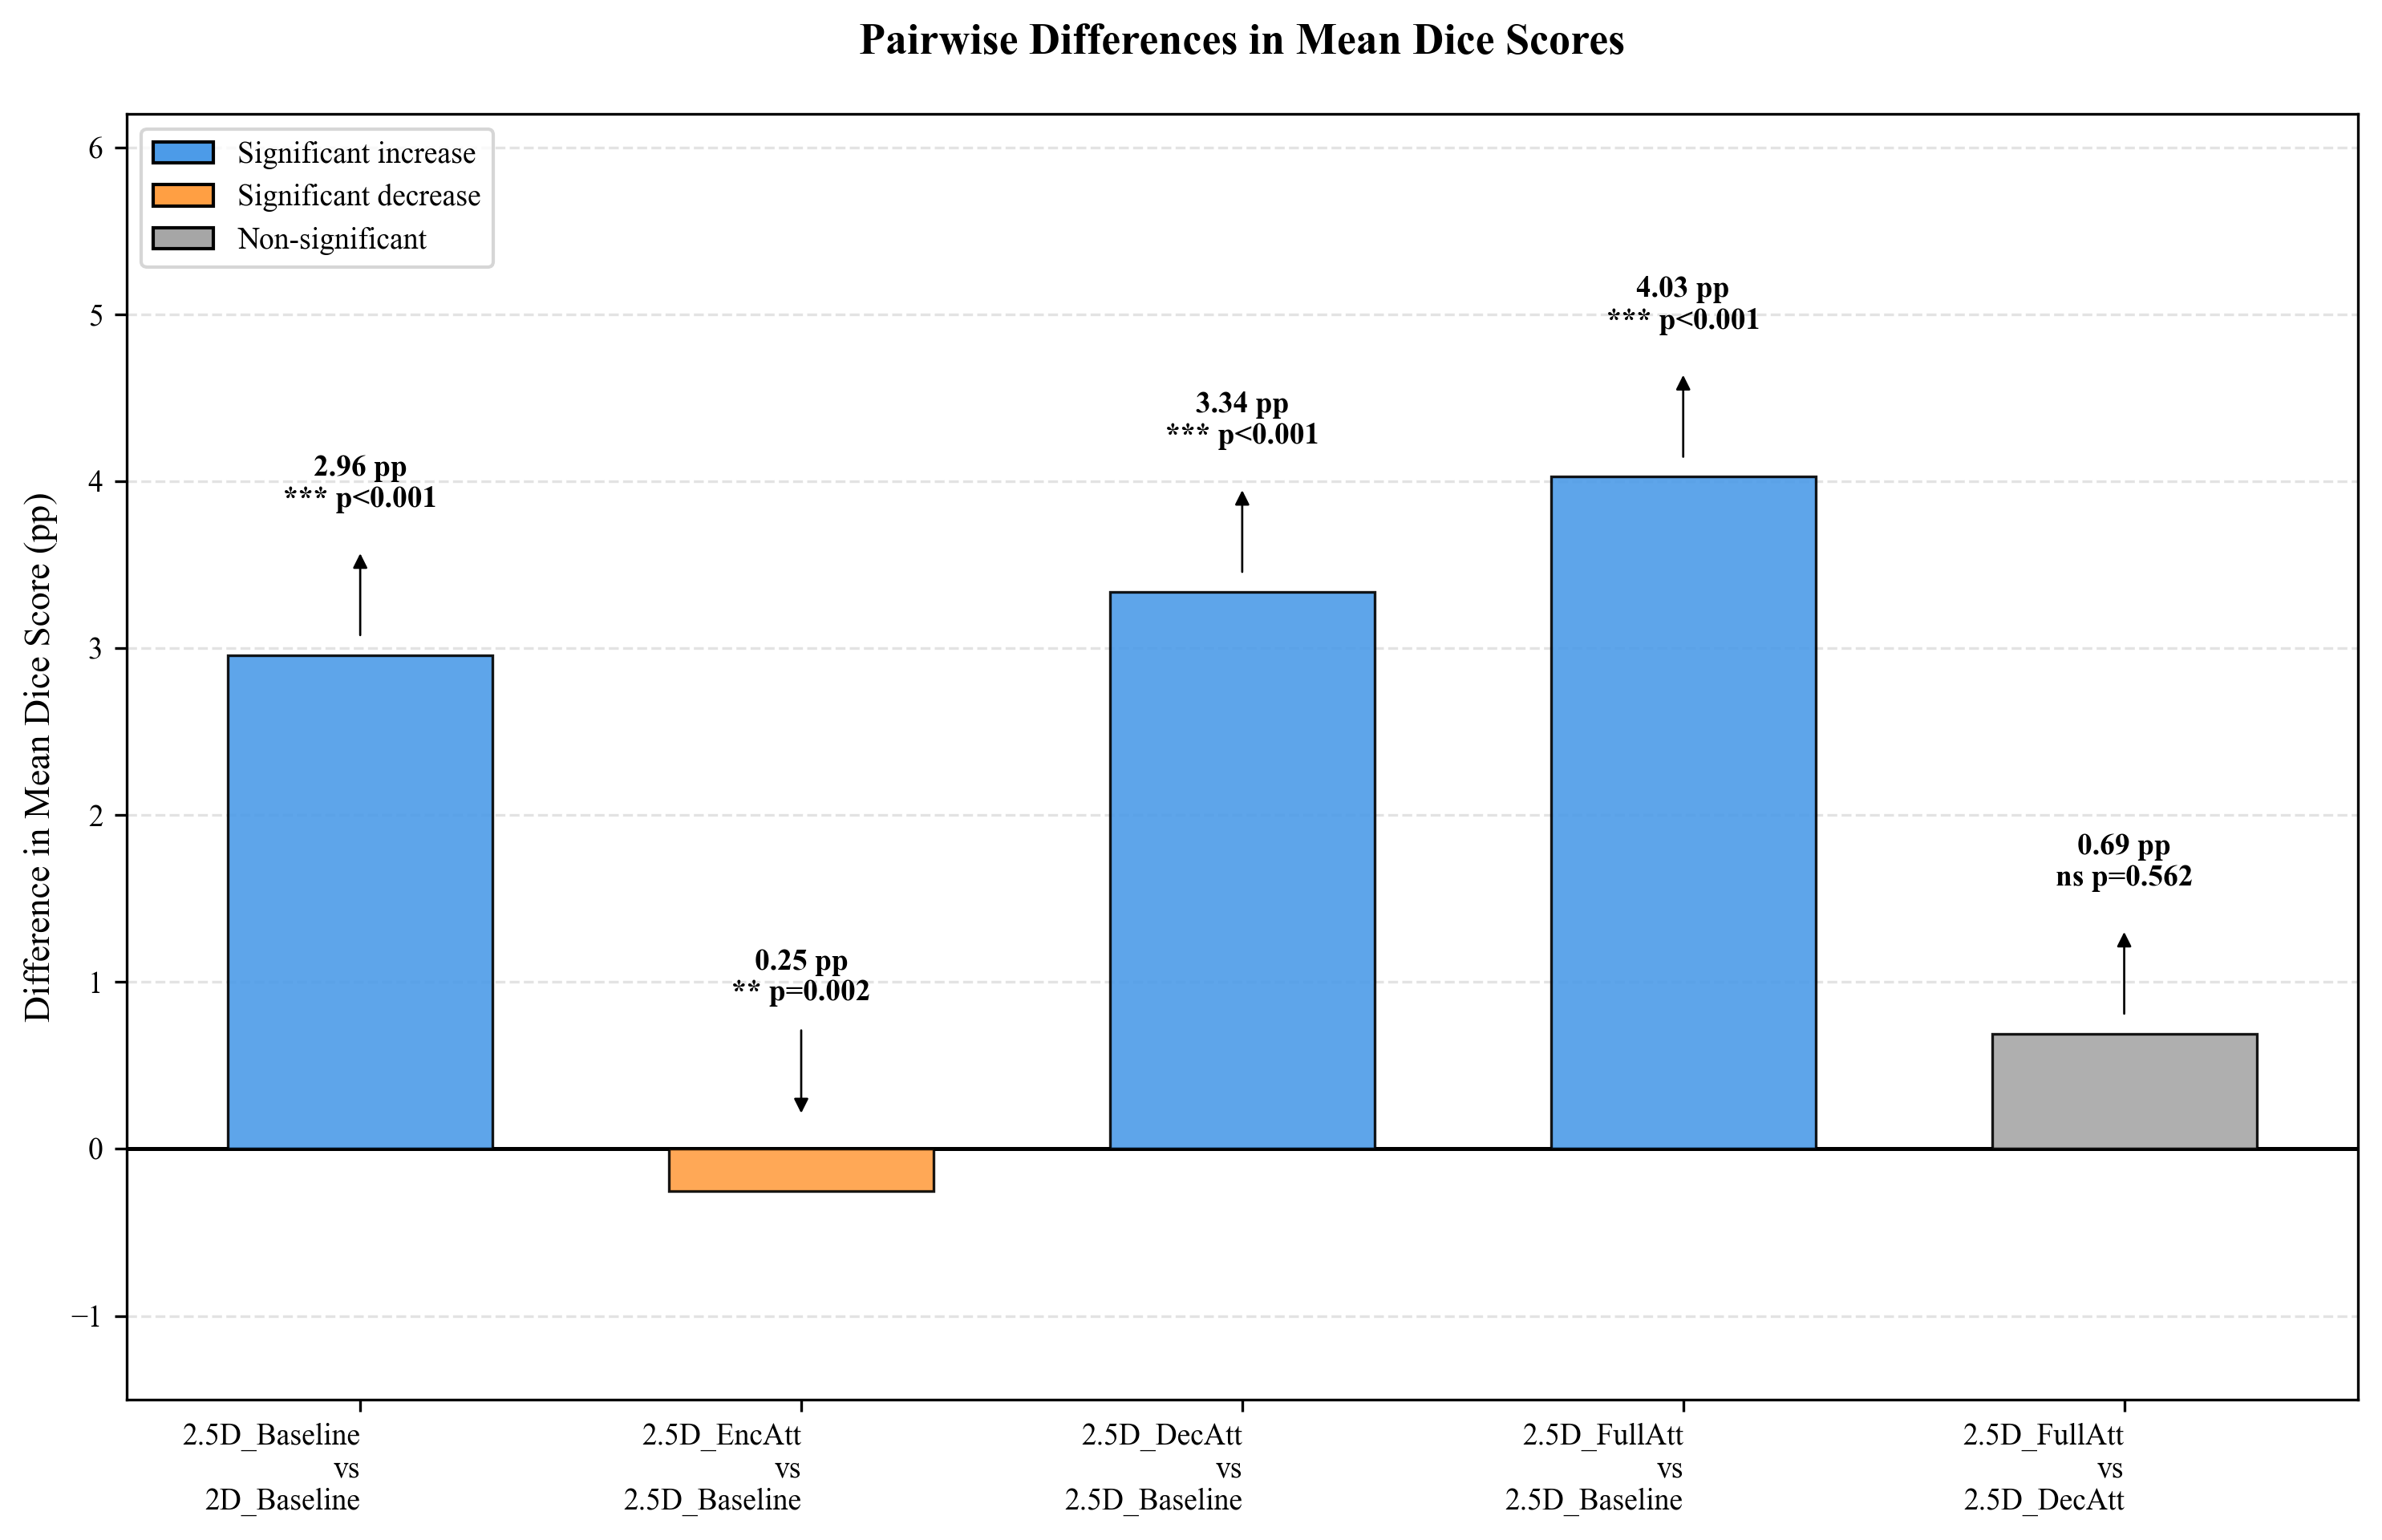

In [ ]:

# ============================================================
# FIGURE 7: Pairwise Differences in Mean Dice Scores
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Comparison order
# ------------------------------------------------------------

comparison_order = [
    "2.5D_Baseline vs 2D_Baseline",
    "2.5D_EncAtt vs 2.5D_Baseline",
    "2.5D_DecAtt vs 2.5D_Baseline",
    "2.5D_FullAtt vs 2.5D_Baseline",
    "2.5D_FullAtt vs 2.5D_DecAtt",
]

comparison_labels = [label.replace(" vs ", "\nvs\n") for label in comparison_order]

# ------------------------------------------------------------
# Retrieve statistical results
# ------------------------------------------------------------

plot_df = (
    wilcoxon_df
    .set_index("Comparison")
    .reindex(comparison_order)
    .reset_index()
)

if plot_df["Mean difference (%)"].isna().any():
    raise ValueError("Some comparisons are missing from wilcoxon_df.")

differences = plot_df["Mean difference (%)"].to_numpy(dtype=float)
adjusted_p = plot_df["Holm-adjusted p-value"].to_numpy(dtype=float)

# ------------------------------------------------------------
# P-value labels
# ------------------------------------------------------------

def get_p_label(p):

    if p < 0.001:
        return "*** p<0.001"

    elif p < 0.01:
        return f"** p={p:.3f}"

    elif p < 0.05:
        return f"* p={p:.3f}"

    else:
        return f"ns p={p:.3f}"


# ------------------------------------------------------------
# Bar colors
# ------------------------------------------------------------

colors = []

for diff, p in zip(differences, adjusted_p):

    if p < 0.05 and diff > 0:
        colors.append("#4C9BE8")

    elif p < 0.05 and diff < 0:
        colors.append("#FF9F43")

    else:
        colors.append("#A6A6A6")


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.rcParams["font.family"] = "Times New Roman"

fig, ax = plt.subplots(figsize=(10, 6.5), dpi=300)

x = np.arange(len(differences))

bars = ax.bar(
    x,
    differences,
    width=0.6,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=3
)

# Zero reference line
ax.axhline(
    0,
    color="black",
    linewidth=1.2,
    zorder=2
)

# ------------------------------------------------------------
# Axis limits
# ------------------------------------------------------------

ax.set_ylim(-1.5, 6.2)

# ------------------------------------------------------------
# Difference labels and directional arrows
# ------------------------------------------------------------

for i, (diff, p) in enumerate(zip(differences, adjusted_p)):

    difference_label = f"{abs(diff):.2f} pp"
    p_label = get_p_label(p)

    # Positive differences: upward arrows
    if diff > 0:

        label_y = diff + 0.85

        ax.annotate(
            "",
            xy=(i, diff + 0.65),       # Arrow head: upper position
            xytext=(i, diff + 0.08),   # Arrow tail: lower position
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                linewidth=0.65,
                mutation_scale=9
            ),
            zorder=5
        )

        ax.text(
            i,
            label_y,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            zorder=6
        )

    # Negative difference: downward arrow
    elif diff < 0:

        label_y = 0.85

        ax.annotate(
            "",
            xy=(i, diff * 0.5 + 0.3),
            xytext=(i, 0.65 + 0.1),       # Arrow tail: upper position
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                linewidth=0.65,
                mutation_scale=9
            ),
            zorder=5
        )

        ax.text(
            i,
            label_y,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            zorder=6
        )

    # Negative difference: downward arrow, label above the bar
    elif diff < 0:

        label_y = 0.85

        ax.annotate(
            "",
            xy=(i, diff + 0.02),
            xytext=(i, 0.48),
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                linewidth=0.65,
                mutation_scale=9
            ),
            zorder=5
        )

        ax.text(
            i,
            label_y,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            zorder=6
        )
    # Negative differences: downward arrow
    elif diff < 0:

        label_y = diff - 0.65

        ax.annotate(
            "",
            xy=(i, diff - 0.04),
            xytext=(i, label_y + 0.12),
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                linewidth=0.75,
                mutation_scale=10,
                shrinkA=2,
                shrinkB=2
            ),
            zorder=5
        )

        ax.text(
            i,
            label_y - 0.05,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="top",
            fontsize=9,
            fontweight="bold",
            zorder=6
        )

        ax.text(
            i,
            label_y + 0.05,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            zorder=6
        )

    # Negative differences: annotation below the bar
    elif diff < 0:

        label_y = 0.85

        ax.annotate(
            "",
            xy=(i, diff * 0.5),       # Arrow tip inside the negative bar
            xytext=(i, 0.65),         # Arrow starts above the bar
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                linewidth=0.65,
                mutation_scale=10
            ),
            zorder=10
        )

        ax.text(
            i,
            label_y,
            f"{difference_label}\n{p_label}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            zorder=11
        )
# ------------------------------------------------------------
# Axis labels and title
# ------------------------------------------------------------

ax.set_xticks(x)

ax.set_xticklabels(
    comparison_labels,
    rotation=0,
    ha="right",
    fontsize=9
)

ax.set_ylabel(
    "Difference in Mean Dice Score (pp)",
    fontsize=11
)

ax.set_title(
    "Pairwise Differences in Mean Dice Scores",
    fontsize=13,
    fontweight="bold",
    pad=18
)

ax.tick_params(axis="y", labelsize=9)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
    zorder=0
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_elements = [
    Patch(
        facecolor="#4C9BE8",
        edgecolor="black",
        label="Significant increase"
    ),
    Patch(
        facecolor="#FF9F43",
        edgecolor="black",
        label="Significant decrease"
    ),
    Patch(
        facecolor="#A6A6A6",
        edgecolor="black",
        label="Non-significant"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper left",
    fontsize=9,
    frameon=True
)

# ------------------------------------------------------------
# Save and display
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "Figure_7_Vertical_Dice_Differences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


